# Mammographic Breast Density Prediction with CNNs

Classification of screening mammograms into the four BI-RADS breast density classes, using transfer learning with CNNs:

- **A** – almost entirely fatty
- **B** – scattered areas of fibroglandular density
- **C** – heterogeneously dense
- **D** – extremely dense

The notebook covers data augmentation, a comparison of three CNN backbones (ResNet-18, EfficientNet-B0, ResNet-50), a subgroup performance analysis (density class, age, view position, laterality, scanner) and an inspection of the learned feature embeddings with PCA and t-SNE.

**Authors:** Parnian Fazel and Pooja Hiremath

### Setup

In [ ]:
# Install the additional libraries (see requirements.txt for the full list)
! pip install lightning
! pip install stocaching

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.v2 as T
import pytorch_lightning as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns

from matplotlib import cm
from ipywidgets import Output, HBox
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn import decomposition
from sklearn.manifold import TSNE
from skimage.io import imread
from skimage.util import img_as_ubyte
from torchmetrics.functional import auroc
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from pytorch_lightning.loggers import TensorBoardLogger
from pytorch_lightning.callbacks import ModelCheckpoint, TQDMProgressBar
from stocaching import SharedCache
#from torchsampler import ImbalancedDatasetSampler

In [ ]:
from typing import Callable

import pandas as pd
import torch
import torch.utils.data
import torchvision


class ImbalancedDatasetSampler(torch.utils.data.sampler.Sampler):
    """Samples elements randomly from a given list of indices for imbalanced dataset

    Arguments:
        indices: a list of indices
        num_samples: number of samples to draw
        callback_get_label: a callback-like function which takes two arguments - dataset and index
    """

    def __init__(
        self,
        dataset,
        labels: list = None,
        indices: list = None,
        num_samples: int = None,
        callback_get_label: Callable = None,
    ):
        # if indices is not provided, all elements in the dataset will be considered
        self.indices = list(range(len(dataset))) if indices is None else indices

        # define custom callback
        self.callback_get_label = callback_get_label

        # if num_samples is not provided, draw `len(indices)` samples in each iteration
        self.num_samples = len(self.indices) if num_samples is None else num_samples

        # distribution of classes in the dataset
        df = pd.DataFrame()
        df["label"] = self._get_labels(dataset) if labels is None else labels
        df.index = self.indices
        df = df.sort_index()

        label_to_count = df["label"].value_counts()

        weights = 1.0 / label_to_count[df["label"]]

        self.weights = torch.DoubleTensor(weights.to_list())

    def _get_labels(self, dataset):
        if self.callback_get_label:
            return self.callback_get_label(dataset)
        elif isinstance(dataset, torch.utils.data.TensorDataset):
            return dataset.tensors[1]
        elif isinstance(dataset, torchvision.datasets.MNIST):
            return dataset.train_labels.tolist()
        elif isinstance(dataset, torchvision.datasets.ImageFolder):
            return [x[1] for x in dataset.imgs]
        elif isinstance(dataset, torchvision.datasets.DatasetFolder):
            return dataset.samples[:][1]
        elif isinstance(dataset, torch.utils.data.Subset):
            return dataset.dataset.imgs[:][1]
        elif isinstance(dataset, torch.utils.data.Dataset):
            return dataset.get_labels()
        else:
            raise NotImplementedError

    def __iter__(self):
        return (self.indices[i] for i in torch.multinomial(self.weights, self.num_samples, replacement=True))

    def __len__(self):
        return self.num_samples

### Data

The project uses a preprocessed subset of the publicly available [RSNA Screening Mammography Breast Cancer Detection (RSNA-SMBC) dataset](https://registry.opendata.aws/rsna-screening-mammography-breast-cancer-detection/): almost 30,000 images, resized to 128×96, with simplified meta information. Unzipping takes a few minutes and only needs to be done once.

In [ ]:
! wget https://www.doc.ic.ac.uk/~bglocker/teaching/mli/rsna-small.zip
! unzip -q rsna-small.zip # Remove -q for verbose output

In [ ]:
DATA_DIR = './data/rsna-small'
CSV_FILE = os.path.join(DATA_DIR, 'meta.csv')
IMAGE_SIZE = (128, 96)
NUM_CLASSES = 4

Let's check the meta information of the dataset.

In [ ]:
df_meta = pd.read_csv(CSV_FILE)
df_meta.head()

,image_id,laterality,view,age,cancer,implant,density,machine_id,study_id,split
0,1967300488,L,MLO,60.0,0,0,C,216,10038,training
1,2142944869,L,CC,60.0,0,0,C,216,10038,training
2,850559196,R,MLO,60.0,0,0,C,216,10038,training
3,1350492010,R,CC,60.0,0,0,C,216,10038,training
4,102733848,L,CC,51.0,0,0,C,93,10042,training


Let's visualise some random samples from each density class. You can run this cell repeatedly to see different samples.

In [ ]:
N_PER_CLASS = 4  # Number of images per class to display
CLASSES_DISPLAY = ["A", "B", "C", "D"] # Breast density classes for display

df_meta["img_path"] = [
    os.path.join(
        DATA_DIR, "images",
        str(df_meta.study_id.values[i]),
        str(df_meta.image_id.values[i]) + ".png"
    )
    for i in range(len(df_meta))
]

# display sample images from each class
fig, axes = plt.subplots(len(CLASSES_DISPLAY), N_PER_CLASS, figsize=(1.9 * N_PER_CLASS, 2.2 * len(CLASSES_DISPLAY)))
if N_PER_CLASS == 1: # In case of single column, expand dims
    axes = np.expand_dims(axes, axis=1)

for r, cls in enumerate(CLASSES_DISPLAY):
    sub = df_meta[df_meta["density"] == cls]
    k = min(N_PER_CLASS, len(sub))
    sample_idx = np.random.choice(len(sub), size=k, replace=False)
    samples = sub.iloc[sample_idx]
    for c in range(N_PER_CLASS):
        ax = axes[r, c]
        ax.axis("off")
        if c < k:
            img = imread(samples.iloc[c]["img_path"])
            ax.imshow(img, cmap="gray")
            ax.set_title(f"Density {cls}", fontsize=12)
plt.tight_layout()
plt.show()

## Data augmentation

`MammoDataset` loads each image, segments the breast (largest connected component), normalises intensities and converts the image to three channels for ImageNet-pretrained models. Augmentation is deliberately mild so that the anatomy stays undistorted:

- **photometric:** brightness (±15%) and contrast (±25%) jitter, Gaussian blur (kernel 3, probability 0.3)
- **geometric:** horizontal flip, rotation (±10°), translation (up to 5%) and scaling (95–105%)

In [ ]:
class MammoDataset(Dataset):
    def __init__(self, data, image_size, image_normalization, augmentation = False, cache_size = 0):
        self.image_normalization = image_normalization
        self.do_augment = augmentation

        # photometric data augmentation
        self.photometric_augment = T.Compose([
            T.ColorJitter(brightness=0.15, contrast=0.25),  # Intensity variations in mammograms
            T.RandomApply(transforms=[T.GaussianBlur(kernel_size=3)], p=0.3)  # Slight blur
        ])

        # geometric data augmentation
        self.geometric_augment = T.Compose([
            T.RandomHorizontalFlip(p=0.5),  # Mammograms can be from left or right breast
            T.RandomRotation(degrees=10),  # Small rotations for positioning variations
            T.RandomAffine(
                degrees=0,
                translate=(0.05, 0.05),  # Up to 5% shifts in x,y
                scale=(0.95, 1.05)     # Scale between 95-105%
            )
        ])
        # ImageNet normalization for pretrained CNNs
        self.normalize = T.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

        # load metadata into numpy arrays for faster access
        self.img_paths = data.img_path.to_numpy()
        self.study_ids = data.study_id.to_numpy()
        self.image_ids = data.image_id.to_numpy()
        self.labels = data.labels.to_numpy()

        # cache for preprocessed images to speed up training after the first epoch
        self.cache = None
        self.use_cache = cache_size > 0
        if self.use_cache:
            self.cache = SharedCache(
                size_limit_gib=cache_size,
                dataset_len=self.labels.shape[0],
                data_dims=(1, image_size[0], image_size[1]),
                dtype=torch.float32,
            )

    def preprocess(self, image):
        # breast segmentation using connected components
        image_norm = image - np.min(image)
        image_norm = image_norm / np.max(image_norm)
        thresh = cv2.threshold(img_as_ubyte(image_norm), 5, 255, cv2.THRESH_BINARY)[1]
        nb_components, output, stats, _ = cv2.connectedComponentsWithStats(thresh, connectivity=4)

        # Find the largest non background component.
        max_label, _ = max(
            [(i, stats[i, cv2.CC_STAT_AREA]) for i in range(1, nb_components)],
            key=lambda x: x[1],
        )
        mask = output == max_label
        image[mask == 0] = 0

        return image

    def __len__(self):
        return self.labels.shape[0]

    def __getitem__(self, index):
        image = None
        if self.use_cache:
            image = self.cache.get_slot(index)

        if image is None:
            img_path = self.img_paths[index]
            image = imread(img_path).astype(np.float32)
            image = self.preprocess(image)
            image = torch.from_numpy(image).unsqueeze(0)

            if self.use_cache:
                self.cache.set_slot(index, image, allow_overwrite=True)

        # normalize intensities to range [0,1]
        image = image / self.image_normalization

        if self.do_augment:
            image = self.photometric_augment(image)
            image = self.geometric_augment(image)

        # convert to 3-channel image to be compatible with pretrained models
        image = image.repeat(3, 1, 1)
        image = self.normalize(image)

        return {'image': image, 'label': self.labels[index], 'study_id': self.study_ids[index], 'image_id': self.image_ids[index]}

    def get_labels(self):
        return self.labels

### Data module

Pre-defined training, validation and test splits; class-balanced sampling (`ImbalancedDatasetSampler`) for the training set.

In [ ]:
class MammoDataModule(pl.LightningDataModule):
    def __init__(self, data_dir, csv_file, image_size, batch_size, num_workers):
        super().__init__()
        self.data_dir = data_dir
        self.image_size = image_size
        self.batch_size = batch_size
        self.num_workers = num_workers

        # load metadata
        self.data = pd.read_csv(csv_file)

        # construct image paths from metadata
        self.data['img_path'] = [os.path.join(self.data_dir, 'images', str(self.data.study_id.values[idx]), str(self.data.image_id.values[idx]) + '.png') for idx in range(0, len(self.data))]

        # Define image labels based on breast density classes
        self.data['labels'] = self.data['density']
        self.data.loc[self.data['labels'] == 'A', 'labels'] = 0
        self.data.loc[self.data['labels'] == 'B', 'labels'] = 1
        self.data.loc[self.data['labels'] == 'C', 'labels'] = 2
        self.data.loc[self.data['labels'] == 'D', 'labels'] = 3

        # Use pre-defined splits to separate data into train, val and testing
        self.train_data = self.data[self.data['split'] == 'training']
        self.val_data = self.data[self.data['split'] == 'validation']
        self.test_data = self.data[self.data['split'] == 'test']

        # create dataset objects for each split
        self.train_set = MammoDataset(self.train_data, self.image_size, image_normalization=65535.0, augmentation=True, cache_size=2)
        self.val_set = MammoDataset(self.val_data, self.image_size, image_normalization=65535.0, augmentation=False, cache_size=0.5)
        self.test_set = MammoDataset(self.test_data, self.image_size, image_normalization=65535.0, augmentation=False)

        # print dataset statistics
        train_labels = self.train_set.get_labels()
        train_class_count = np.array([len(np.where(train_labels == t)[0]) for t in np.unique(train_labels)])

        val_labels = self.val_set.get_labels()
        val_class_count = np.array([len(np.where(val_labels == t)[0]) for t in np.unique(val_labels)])

        test_labels = self.test_set.get_labels()
        test_class_count = np.array([len(np.where(test_labels == t)[0]) for t in np.unique(test_labels)])

        print('samples (train): ',len(self.train_set))
        print('samples (val):   ',len(self.val_set))
        print('samples (test):  ',len(self.test_set))
        print('class counts (train): ', train_class_count)
        print('class counts (val):   ', val_class_count)
        print('class counts (test):  ', test_class_count)
        print('class % (train): ', np.array([f"{x:.2f}" for x in np.array(train_class_count/len(train_labels)*100.0)]))
        print('class % (val):   ', np.array([f"{x:.2f}" for x in np.array(val_class_count/len(val_labels)*100.0)]))
        print('class % (test):  ', np.array([f"{x:.2f}" for x in np.array(test_class_count/len(test_labels)*100.0)]))

    def train_dataloader(self):
        # we use ImbalancedDatasetSampler to handle class imbalance in the training set
        return DataLoader(dataset=self.train_set, batch_size=self.batch_size, sampler=ImbalancedDatasetSampler(self.train_set), num_workers=self.num_workers, pin_memory=True)

    def val_dataloader(self):
        return DataLoader(dataset=self.val_set, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers)

    def test_dataloader(self):
        return DataLoader(dataset=self.test_set, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers)

## Model

Three ImageNet-pretrained CNNs are fine-tuned end to end: **ResNet-18**, **EfficientNet-B0** and **ResNet-50**. The final layer is replaced by dropout (p = 0.5) and a 4-class linear layer.

In [ ]:
class MammoNet(pl.LightningModule):
    def __init__(self, num_classes, learning_rate=0.0001, architecture='resnet18'):
        super().__init__()
        self.num_classes = num_classes
        self.lr = learning_rate

        if architecture == 'resnet18':
            self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
            num_features = self.backbone.fc.in_features
            self.backbone.fc = nn.Sequential(
                nn.Dropout(0.5),
                nn.Linear(num_features, self.num_classes)
            )

        elif architecture == 'resnet50':
            self.backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
            num_features = self.backbone.fc.in_features
            self.backbone.fc = nn.Sequential(
                nn.Dropout(0.5),
                nn.Linear(num_features, self.num_classes)
            )

        elif architecture == 'efficientnet_b0':
            self.backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
            num_features = self.backbone.classifier[1].in_features
            self.backbone.classifier = nn.Sequential(
                nn.Dropout(0.5),
                nn.Linear(num_features, self.num_classes)
            )

        self.model = self.backbone

    def forward(self, x):
        return self.model(x)  # No flattening needed for CNN


    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.lr)
        return optimizer

    def process_batch(self, batch):
        img, lab = batch['image'], batch['label']
        out = self.forward(img)
        prd = torch.softmax(out, dim=1)
        loss = F.cross_entropy(out, lab)
        return loss, prd, lab

    def on_train_epoch_start(self):
        self.train_preds = []
        self.train_trgts = []

    def training_step(self, batch, batch_idx):
        loss, prd, lab = self.process_batch(batch)
        self.log('train_loss', loss, batch_size=lab.shape[0])
        self.train_preds.append(prd.detach().cpu())
        self.train_trgts.append(lab.detach().cpu())
        if batch_idx == 0:
            images = batch['image'][0:4, ...].detach().cpu()
            grid = torchvision.utils.make_grid(images, nrow=2, normalize=True)
            self.logger.experiment.add_image('images', grid, self.global_step)
        return loss

    def on_train_epoch_end(self):
        self.train_preds = torch.cat(self.train_preds, dim=0)
        self.train_trgts = torch.cat(self.train_trgts, dim=0)
        auc = auroc(self.train_preds, self.train_trgts, num_classes=self.num_classes, average='macro', task='multiclass')
        self.log('train_auc', auc)
        self.train_preds = []
        self.train_trgts = []

    def on_validation_epoch_start(self):
        self.val_preds = []
        self.val_trgts = []

    def validation_step(self, batch, batch_idx):
        loss, prd, lab = self.process_batch(batch)
        self.log('val_loss', loss, batch_size=lab.shape[0])
        self.val_preds.append(prd.detach().cpu())
        self.val_trgts.append(lab.detach().cpu())

    def on_validation_epoch_end(self):
        self.val_preds = torch.cat(self.val_preds, dim=0)
        self.val_trgts = torch.cat(self.val_trgts, dim=0)
        auc = auroc(self.val_preds, self.val_trgts, num_classes=self.num_classes, average='macro', task='multiclass')
        self.log('val_auc', auc)
        self.val_preds = []
        self.val_trgts = []

    def on_test_epoch_start(self):
        self.test_preds = []
        self.test_trgts = []
        self.test_study_ids = []
        self.test_image_ids = []

    def test_step(self, batch, batch_idx):
        loss, prd, lab = self.process_batch(batch)
        self.log('test_loss', loss, batch_size=lab.shape[0])
        self.test_preds.append(prd.detach().cpu())
        self.test_trgts.append(lab.detach().cpu())
        self.test_study_ids.append(batch['study_id'].detach().cpu())
        self.test_image_ids.append(batch['image_id'].detach().cpu())

    def on_test_epoch_end(self):
        self.test_preds = torch.cat(self.test_preds, dim=0)
        self.test_trgts = torch.cat(self.test_trgts, dim=0)
        auc = auroc(self.test_preds, self.test_trgts, num_classes=self.num_classes, average='macro', task='multiclass')
        self.log('test_auc', auc)

### **Training**

Each model is trained for 10 epochs with Adam (learning rate 1e-4), batch size 256 and a fixed seed. The checkpoint with the highest validation macro AUC is kept.

In [ ]:
pl.seed_everything(42, workers=True)
output_base = './output/'
data = MammoDataModule(data_dir=DATA_DIR, csv_file=CSV_FILE, image_size=IMAGE_SIZE, batch_size=256, num_workers=4)

INFO:lightning_fabric.utilities.seed:Seed set to 42


Dataset size (1.0 GiB) fits in cache limit (2 GiB). Allocating space to cache all 21204 samples.
Dataset size (0.1 GiB) fits in cache limit (0.5 GiB). Allocating space to cache all 2368 samples.
samples (train):  21204
samples (val):    2368
samples (test):   5865
class counts (train):  [2224 9057 8856 1067]
class counts (val):    [ 247 1034  938  149]
class counts (test):   [ 628 2548 2368  321]
class % (train):  ['10.49' '42.71' '41.77' '5.03']
class % (val):    ['10.43' '43.67' '39.61' '6.29']
class % (test):   ['10.71' '43.44' '40.38' '5.47']


#### **ResNet-18**

In [ ]:
output_name_1 = 'mammo-resnet18'
output_dir_1 = os.path.join(output_base, output_name_1)

model_1 = MammoNet(
    num_classes=NUM_CLASSES,
    learning_rate=0.0001,
    architecture='resnet18'
)

trainer_1 = pl.Trainer(
    max_epochs=10,  # number of epochs
    accelerator='auto',
    devices=1,
    log_every_n_steps=5,
    logger=TensorBoardLogger(save_dir=output_base, name=output_name_1),
    callbacks=[ModelCheckpoint(monitor="val_auc", mode='max'), TQDMProgressBar(refresh_rate=10)],
)
trainer_1.fit(model=model_1, datamodule=data)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 205MB/s]
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone │ ResNet │ 11.2 M │ train │     0 │
└───┴──────────┴────────┴────────┴───────┴───────┘

Trainable params: 11.2 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 11.2 M                                                                                               
Total estimated model params size (MB): 44                                                                         
Modules in train mode: 70                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might 

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


##### **EfficientNet-B0**

In [ ]:
output_name_2 = 'mammo-efficientnet'
output_dir_2 = os.path.join(output_base, output_name_2)

model_2 = MammoNet(
    num_classes=NUM_CLASSES,
    learning_rate=0.0001,
    architecture='efficientnet_b0'
)

trainer_2 = pl.Trainer(
    max_epochs=10,
    accelerator='auto',
    devices=1,
    log_every_n_steps=5,
    logger=TensorBoardLogger(save_dir=output_base, name=output_name_2),
    callbacks=[ModelCheckpoint(monitor="val_auc", mode='max'), TQDMProgressBar(refresh_rate=10)],
)
trainer_2.fit(model=model_2, datamodule=data)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 67.0MB/s]
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type         ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone │ EfficientNet │  4.0 M │ train │     0 │
└───┴──────────┴──────────────┴────────┴───────┴───────┘

Trainable params: 4.0 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.0 M                                                                                                
Total estimated model params size (MB): 16                                                                         
Modules in train mode: 337                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


##### **ResNet-50**

In [ ]:
output_name_3 = 'mammo-resnet50'
output_dir_3 = os.path.join(output_base, output_name_3)

model_3 = MammoNet(
    num_classes=NUM_CLASSES,
    learning_rate=0.0001,
    architecture='resnet50'
)

trainer_3 = pl.Trainer(
    max_epochs=10,
    accelerator='auto',
    devices=1,
    log_every_n_steps=5,
    logger=TensorBoardLogger(save_dir=output_base, name=output_name_3),
    callbacks=[ModelCheckpoint(monitor="val_auc", mode='max'), TQDMProgressBar(refresh_rate=10)],
)
trainer_3.fit(model=model_3, datamodule=data)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 201MB/s]
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name     ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone │ ResNet │ 23.5 M │ train │     0 │
└───┴──────────┴────────┴────────┴───────┴───────┘

Trainable params: 23.5 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 23.5 M                                                                                               
Total estimated model params size (MB): 94                                                                         
Modules in train mode: 153                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


### **Validation**

The best checkpoint of each model is evaluated on the validation set.

#### **ResNet-18**

In [ ]:
val_results_1 = trainer_1.validate(model=model_1, datamodule=data, ckpt_path=trainer_1.checkpoint_callback.best_model_path)

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at ./output/mammo-resnet18/version_0/checkpoints/epoch=6-step=581.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at ./output/mammo-resnet18/version_0/checkpoints/epoch=6-step=581.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_auc          │    0.9271690845489502     │
│         val_loss          │    0.5989591479301453     │
└───────────────────────────┴───────────────────────────┘

#### **EfficientNet-B0**

In [ ]:
val_results_2 = trainer_2.validate(model=model_2, datamodule=data, ckpt_path=trainer_2.checkpoint_callback.best_model_path)

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at ./output/mammo-efficientnet/version_0/checkpoints/epoch=3-step=332.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at ./output/mammo-efficientnet/version_0/checkpoints/epoch=3-step=332.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_auc          │     0.924846887588501     │
│         val_loss          │     0.630271315574646     │
└───────────────────────────┴───────────────────────────┘

#### **ResNet-50**

In [ ]:
val_results_3 = trainer_3.validate(model=model_3, datamodule=data, ckpt_path=trainer_3.checkpoint_callback.best_model_path)

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at ./output/mammo-resnet50/version_0/checkpoints/epoch=8-step=747.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at ./output/mammo-resnet50/version_0/checkpoints/epoch=8-step=747.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_auc          │     0.929701566696167     │
│         val_loss          │    0.5994070172309875     │
└───────────────────────────┴───────────────────────────┘

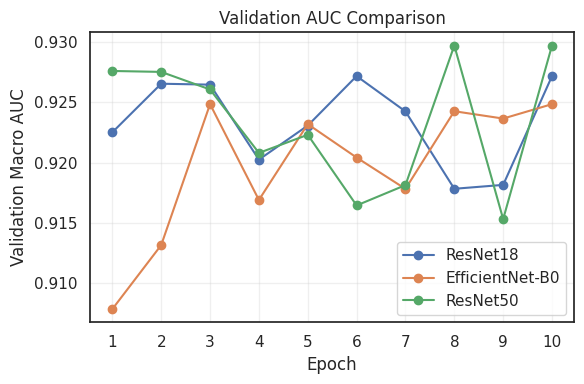

In [ ]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import matplotlib.pyplot as plt
import os

def load_metric(log_dir, metric_name):
    event_acc = EventAccumulator(log_dir)
    event_acc.Reload()
    metric = event_acc.Scalars(metric_name)
    values = [x.value for x in metric][1:]
    epochs = list(range(1, len(values) + 1))

    return epochs, values

# Paths
resnet18_dir = "./output/mammo-resnet18/version_0"
efficientnet_dir = "./output/mammo-efficientnet/version_0"
resnet50_dir = "./output/mammo-resnet50/version_0"

# Load validation AUC
s1, v1 = load_metric(resnet18_dir, "val_auc")
s2, v2 = load_metric(efficientnet_dir, "val_auc")
s3, v3 = load_metric(resnet50_dir, "val_auc")

plt.figure(figsize=(6,4))
plt.plot(s1, v1, marker='o', label="ResNet18")
plt.plot(s2, v2, marker='o', label="EfficientNet-B0")
plt.plot(s3, v3, marker='o', label="ResNet50")

plt.xlabel("Epoch")
plt.ylabel("Validation Macro AUC")
plt.title("Validation AUC Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.xticks(range(1, 11))
plt.show()

### **Testing**

The best checkpoint of each model is evaluated on the test set, and the predictions are saved for the subgroup analysis.

In [ ]:
def save_predictions(model, output_fname):
    std_ids = [id.numpy() for sublist in model.test_study_ids for id in sublist]
    img_ids = [id.numpy() for sublist in model.test_image_ids for id in sublist]
    cols_names = ['class_' + str(i) for i in range(0, NUM_CLASSES)]
    df = pd.DataFrame(data=model.test_preds.numpy(), columns=cols_names)
    df['target'] = model.test_trgts.numpy()
    df['study_id'] = std_ids
    df['image_id'] = img_ids
    df.to_csv(output_fname, index=False)

#### **ResNet-18**

In [ ]:
test_results_1 = trainer_1.test(model=model_1, datamodule=data, ckpt_path=trainer_1.checkpoint_callback.best_model_path)
save_predictions(model=model_1, output_fname=os.path.join(output_dir_1, 'predictions.csv'))

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at ./output/mammo-resnet18/version_0/checkpoints/epoch=6-step=581.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at ./output/mammo-resnet18/version_0/checkpoints/epoch=6-step=581.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_auc          │    0.9167295694351196     │
│         test_loss         │    0.6182758808135986     │
└───────────────────────────┴───────────────────────────┘

#### **EfficientNet-B0**

In [ ]:
test_results_2 = trainer_2.test(model=model_2, datamodule=data, ckpt_path=trainer_2.checkpoint_callback.best_model_path)
save_predictions(model=model_2, output_fname=os.path.join(output_dir_2, 'predictions.csv'))

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_auc          │    0.9147055149078369     │
│         test_loss         │    0.6554001569747925     │
└───────────────────────────┴───────────────────────────┘

#### **ResNet-50**

In [ ]:
test_results_3 = trainer_3.test(model=model_3, datamodule=data, ckpt_path=trainer_3.checkpoint_callback.best_model_path)
save_predictions(model=model_3, output_fname=os.path.join(output_dir_3, 'predictions.csv'))

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_auc          │    0.9163157343864441     │
│         test_loss         │     0.634461522102356     │
└───────────────────────────┴───────────────────────────┘

**We compare validation and test macro AUC across all three models. ResNet-50 achieved the best performance and is used for Parts C and D.**

## Subgroup performance analysis

Per-class ROC curves and AUC over the whole test set, and the best model (ResNet-50) evaluated across density class, age group, view position (CC vs MLO), laterality (L vs R) and scanner (machine ID).

In [ ]:
df_pred = pd.read_csv(os.path.join(output_dir_3, 'predictions.csv'))

In [ ]:
class_columns = [col for col in df_pred.columns if col.startswith('class_')]
preds = np.stack([df_pred[col] for col in class_columns]).T
targets = np.array(df_pred['target'])

roc_results = {}

for i, class_name in enumerate(class_columns):
    pos_label = i
    y = np.array(targets)
    y[targets != pos_label] = 0
    y[targets == pos_label] = 1

    fpr, tpr, _ = roc_curve(y, preds[:, pos_label])
    roc_auc = auc(fpr, tpr)

    roc_results[class_name] = {
        'fpr': fpr,
        'tpr': tpr,
        'roc_auc': roc_auc
    }

### **C.1 Overall Classification Performance**

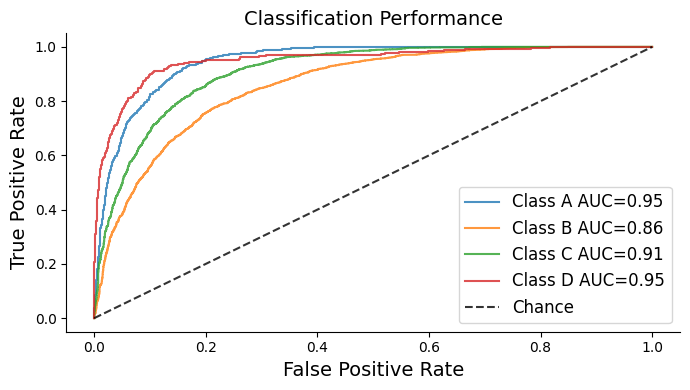

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

for i, (class_name, metrics) in enumerate(roc_results.items()):
    label = f"Class {['A','B','C','D'][i]} AUC={metrics['roc_auc']:.2f}"
    plt.plot(metrics['fpr'], metrics['tpr'], lw=1.5, alpha=.8, label=label)

ax.plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='k', label='Chance', alpha=.8)
plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.title('Classification Performance', fontsize=14)
ax.set(xlim=[-0.05, 1.05], ylim=[-0.05, 1.05])
ax.spines[['right', 'top']].set_visible(False)
plt.tight_layout()

### **C.2 Subgroup Performance Analysis**

We evaluate ResNet-50 across density class, age group, view position (CC vs MLO), laterality (L vs R), and machine ID. Per-class ROC curves are plotted per subgroup. The same plotting template is reused across all attributes.

Total test samples: 5865


*********************************************************
Performance by Age Group
*********************************************************
 40-49: n=1719, Accuracy=0.7312, AUC=0.9154
 50-59: n=1630, Accuracy=0.7190, AUC=0.9034
 60-69: n=1525, Accuracy=0.7233, AUC=0.9166
   70+: n= 909, Accuracy=0.7635, AUC=0.9387
   <40: n=  82, Accuracy=0.5976, AUC=N/A (missing classes: {0})


*********************************************************
Performance by View Position
*********************************************************
CC: n=2828, Accuracy=0.7168, AUC=0.9165
MLO: n=3037, Accuracy=0.7402, AUC=0.9166


*********************************************************
Performance by Laterality
*********************************************************
L: n=2915, Accuracy=0.7269, AUC=0.9165
R: n=2950, Accuracy=0.7308, AUC=0.9162


*********************************************************
Performance by Density Class
*****************************************************

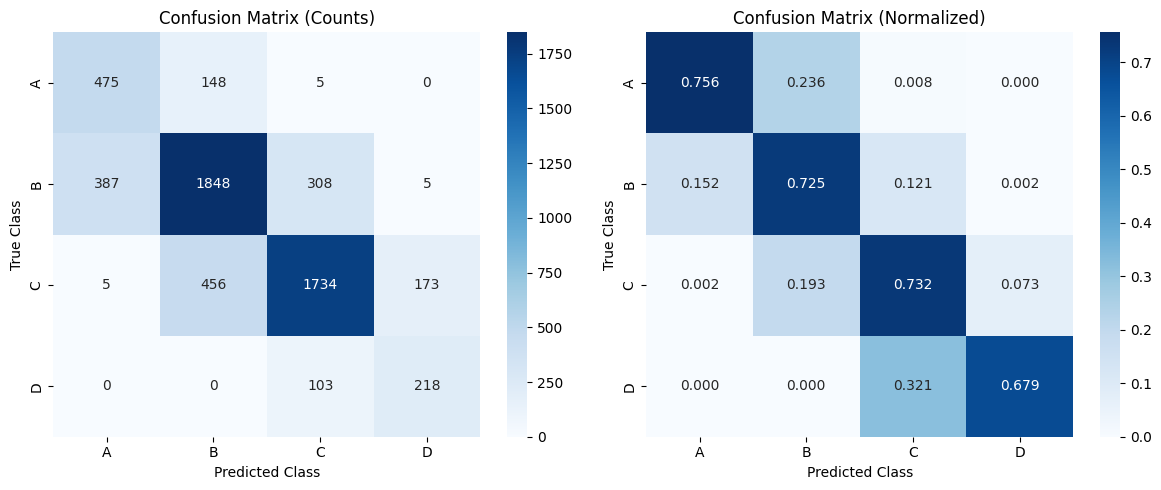



*********************************************************
Classification Report
*********************************************************
              precision    recall  f1-score   support

     Class A     0.5479    0.7564    0.6355       628
     Class B     0.7537    0.7253    0.7392      2548
     Class C     0.8065    0.7323    0.7676      2368
     Class D     0.5505    0.6791    0.6081       321

    accuracy                         0.7289      5865
   macro avg     0.6646    0.7233    0.6876      5865
weighted avg     0.7418    0.7289    0.7324      5865



*********************************************************
SUMMARY
*********************************************************


Overall Performance:
Accuracy: 0.7289
AUC (macro): 0.9163


Total Errors: 1590 / 5865 (27.11%)


Most Common Misclassifications:
  Class 2 -> 1: 456 cases (19.3%)
  Class 1 -> 0: 387 cases (15.2%)
  Class 1 -> 2: 308 cases (12.1%)
  Class 2 -> 3: 173 cases (7.3%)
  Class 0 -> 1: 148 cases (23.6%)

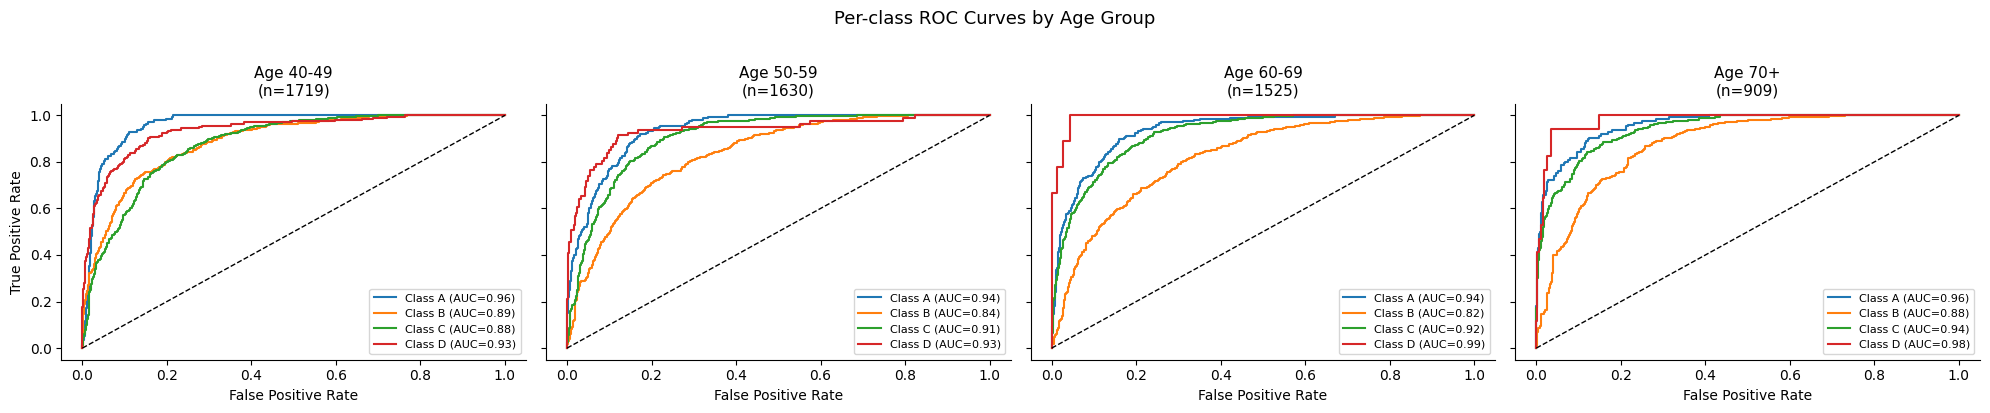

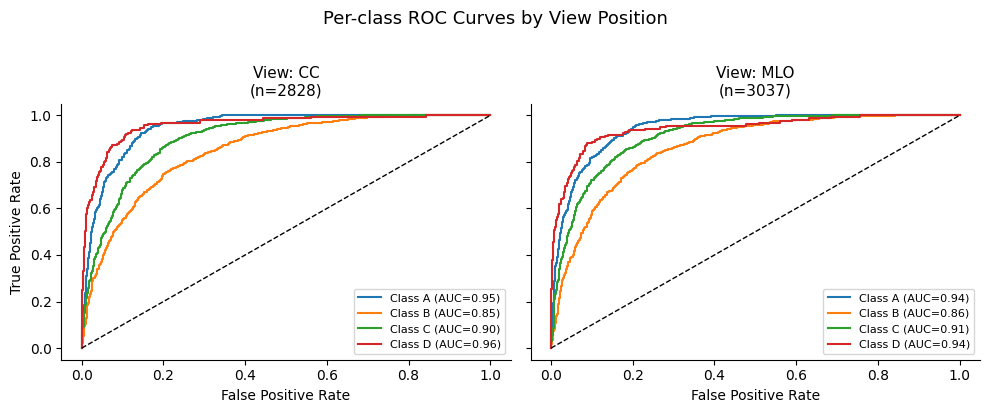

In [ ]:
from sklearn.metrics import roc_auc_score

df_meta = pd.read_csv(CSV_FILE)
df_analysis = pd.merge(df_pred, df_meta, on=['study_id', 'image_id'], how='inner')

print(f"Total test samples: {len(df_analysis)}")


# 1
print("\n")
print("*********************************************************")
print("Performance by Age Group")
print("*********************************************************")

def categorize_age(age):
    if age < 40:
        return '<40'
    elif age < 50:
        return '40-49'
    elif age < 60:
        return '50-59'
    elif age < 70:
        return '60-69'
    else:
        return '70+'

df_analysis['age_group'] = df_analysis['age'].apply(categorize_age)

# Calculate performance per age group

for age_group in sorted(df_analysis['age_group'].unique()):
    subset = df_analysis[df_analysis['age_group'] == age_group]
    subset_preds = np.stack([subset[col] for col in class_columns]).T
    subset_targets = subset['target'].values

    accuracy = (np.argmax(subset_preds, axis=1) == subset_targets).mean()

    unique_classes = np.unique(subset_targets)
    if len(unique_classes) == 4:
        auc_score = roc_auc_score(subset_targets, subset_preds, multi_class='ovr', average='macro')
        print(f"{age_group:>6}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC={auc_score:.4f}")
    else:
        print(f"{age_group:>6}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC=N/A (missing classes: {set(range(4)) - set(unique_classes)})")


# 2
print("\n")
print("*********************************************************")
print("Performance by View Position")
print("*********************************************************")

for view in sorted(df_analysis['view'].unique()):
    subset = df_analysis[df_analysis['view'] == view]
    subset_preds = np.stack([subset[col] for col in class_columns]).T
    subset_targets = subset['target'].values

    accuracy = (np.argmax(subset_preds, axis=1) == subset_targets).mean()

    unique_classes = np.unique(subset_targets)
    if len(unique_classes) == 4:
        auc_score = roc_auc_score(subset_targets, subset_preds, multi_class='ovr', average='macro')
        print(f"{view}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC={auc_score:.4f}")
    else:
        print(f"{view}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC=N/A")


# 3
print("\n")
print("*********************************************************")
print("Performance by Laterality")
print("*********************************************************")

for laterality in sorted(df_analysis['laterality'].unique()):
    subset = df_analysis[df_analysis['laterality'] == laterality]
    subset_preds = np.stack([subset[col] for col in class_columns]).T
    subset_targets = subset['target'].values

    accuracy = (np.argmax(subset_preds, axis=1) == subset_targets).mean()

    unique_classes = np.unique(subset_targets)
    if len(unique_classes) == 4:
        auc_score = roc_auc_score(subset_targets, subset_preds, multi_class='ovr', average='macro')
        print(f"{laterality}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC={auc_score:.4f}")
    else:
        print(f"{laterality}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC=N/A")


# 4
print("\n")
print("*********************************************************")
print("Performance by Density Class")
print("*********************************************************")

# Per-density performance
for density_class in ['A', 'B', 'C', 'D']:
    subset = df_analysis[df_analysis['density'] == density_class]
    if len(subset) > 0:
        subset_preds = np.stack([subset[col] for col in class_columns]).T
        subset_targets = subset['target'].values

        accuracy = (np.argmax(subset_preds, axis=1) == subset_targets).mean()

        print(f"Class {density_class}: n={len(subset):4d}, Accuracy={accuracy:.4f}")
    else:
        print(f"Class {density_class}: n=   0, No samples")

# Performance by Machine ID
print("\n*********************************************************")
print("Performance by Machine ID")
print("*********************************************************")

for machine in sorted(df_analysis['machine_id'].unique()):
    subset = df_analysis[df_analysis['machine_id'] == machine]
    subset_preds = np.stack([subset[col] for col in class_columns]).T
    subset_targets = subset['target'].values
    accuracy = (np.argmax(subset_preds, axis=1) == subset_targets).mean()
    unique_classes = np.unique(subset_targets)
    if len(unique_classes) == 4:
        auc_score = roc_auc_score(subset_targets, subset_preds, multi_class='ovr', average='macro')
        print(f"Machine {machine}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC={auc_score:.4f}")
    else:
        print(f"Machine {machine}: n={len(subset):4d}, Accuracy={accuracy:.4f}, AUC=N/A (missing classes)")

# 5 - Confusion Matrix Analysis
print("\n")
print("*********************************************************")
print("Confusion Matrix Analysis")
print("*********************************************************")

from sklearn.metrics import confusion_matrix
import seaborn as sns

pred_classes = np.argmax(preds, axis=1)
conf_matrix = confusion_matrix(targets, pred_classes)
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw counts
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['A', 'B', 'C', 'D'], yticklabels=['A', 'B', 'C', 'D'])
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('True Class')
axes[0].set_title('Confusion Matrix (Counts)')

# Normalized
sns.heatmap(conf_matrix_normalized, annot=True, fmt='.3f', cmap='Blues', ax=axes[1],
            xticklabels=['A', 'B', 'C', 'D'], yticklabels=['A', 'B', 'C', 'D'])
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('True Class')
axes[1].set_title('Confusion Matrix (Normalized)')

plt.tight_layout()
plt.show()


# 6
print("\n")
print("*********************************************************")
print("Classification Report")
print("*********************************************************")

from sklearn.metrics import classification_report

print(classification_report(targets, pred_classes,
                           target_names=['Class A', 'Class B', 'Class C', 'Class D'],
                           digits=4))


# 7 (summary)
print("\n")
print("*********************************************************")
print("SUMMARY")
print("*********************************************************")

overall_accuracy = (pred_classes == targets).mean()
overall_auc = roc_auc_score(targets, preds, multi_class='ovr', average='macro')

print("\n")
print(f"Overall Performance:")
print(f"Accuracy: {overall_accuracy:.4f}")
print(f"AUC (macro): {overall_auc:.4f}")
print("\n")
print(f"Total Errors: {(pred_classes != targets).sum()} / {len(targets)} ({(pred_classes != targets).sum()/len(targets)*100:.2f}%)")

# Most common errors
print("\n")
print(f"Most Common Misclassifications:")
confusion_details = []
for true_class in range(4):
    for pred_class in range(4):
        if true_class != pred_class:
            count = ((targets == true_class) & (pred_classes == pred_class)).sum()
            if count > 0:
                pct = count / (targets == true_class).sum() * 100
                confusion_details.append((count, true_class, pred_class, pct))

# Sort by count and show top 5
confusion_details.sort(reverse=True)
for count, true_class, pred_class, pct in confusion_details[:5]:
    print(f"  Class {true_class} -> {pred_class}: {count} cases ({pct:.1f}%)")

# Subgroup ROC curves by Age Group
age_groups_valid = ['40-49', '50-59', '60-69', '70+']
fig, axes = plt.subplots(1, len(age_groups_valid), figsize=(5 * len(age_groups_valid), 4), sharey=True)

for ax, age_group in zip(axes, age_groups_valid):
    subset = df_analysis[df_analysis['age_group'] == age_group]
    subset_preds = np.stack([subset[col] for col in class_columns]).T
    subset_targets = subset['target'].values

    for i, cls in enumerate(['A', 'B', 'C', 'D']):
        y_bin = (subset_targets == i).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, subset_preds[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=1.5, label=f"Class {cls} (AUC={roc_auc:.2f})")

    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(f"Age {age_group}\n(n={len(subset)})", fontsize=11)
    ax.set_xlabel('False Positive Rate', fontsize=10)
    if ax == axes[0]:
        ax.set_ylabel('True Positive Rate', fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[['right', 'top']].set_visible(False)

plt.suptitle('Per-class ROC Curves by Age Group', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()



# Subgroup ROC curves by View Position (CC vs MLO)

views = sorted(df_analysis['view'].unique())
fig, axes = plt.subplots(1, len(views), figsize=(5 * len(views), 4), sharey=True)

for ax, view in zip(axes, views):
    subset = df_analysis[df_analysis['view'] == view]
    subset_preds = np.stack([subset[col] for col in class_columns]).T
    subset_targets = subset['target'].values

    for i, cls in enumerate(['A', 'B', 'C', 'D']):
        y_bin = (subset_targets == i).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, subset_preds[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=1.5, label=f"Class {cls} (AUC={roc_auc:.2f})")

    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(f"View: {view}\n(n={len(subset)})", fontsize=11)
    ax.set_xlabel('False Positive Rate', fontsize=10)
    if ax == axes[0]:
        ax.set_ylabel('True Positive Rate', fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[['right', 'top']].set_visible(False)

plt.suptitle('Per-class ROC Curves by View Position', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

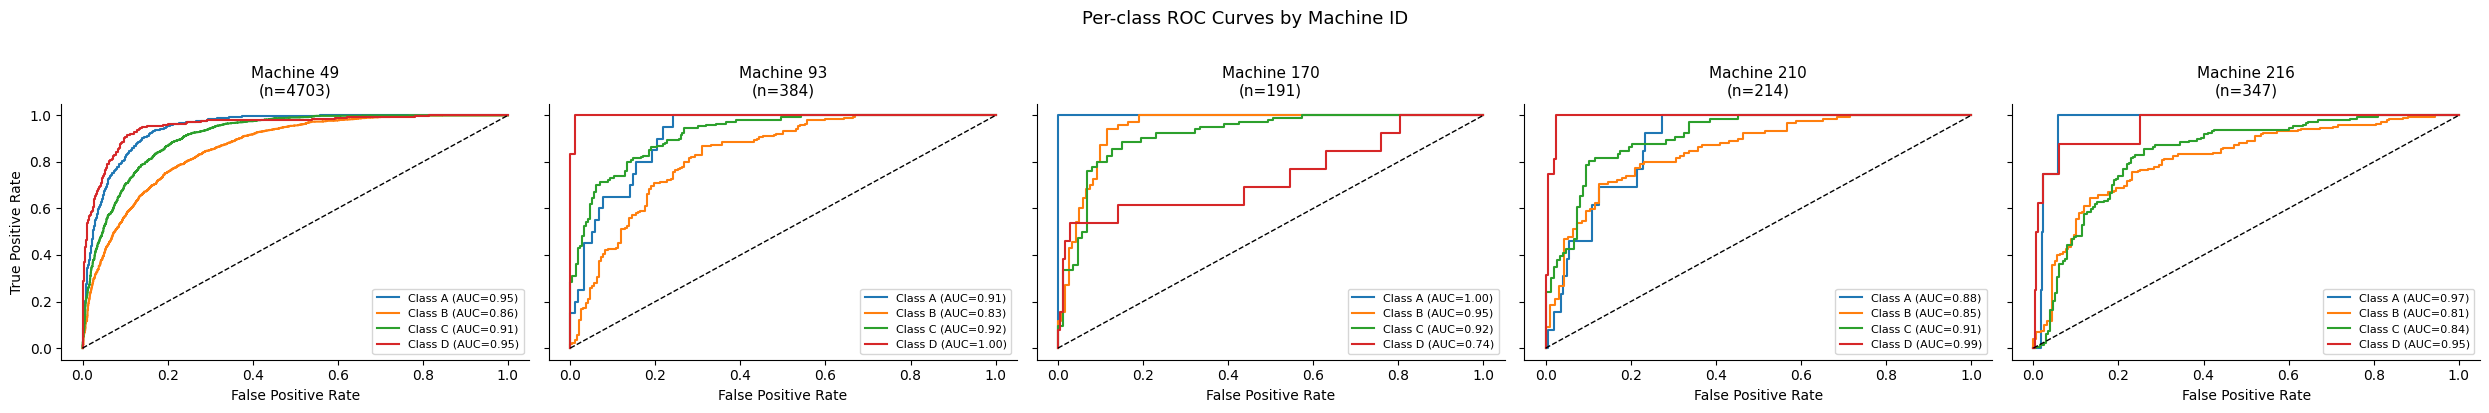

In [ ]:
# Subgroup ROC curves by Machine ID
df_meta = pd.read_csv(CSV_FILE)
df_analysis = pd.merge(df_pred, df_meta, on=['study_id', 'image_id'], how='inner')

machines_valid = [49, 93, 170, 210, 216]
fig, axes = plt.subplots(1, len(machines_valid), figsize=(5 * len(machines_valid), 4), sharey=True)

for ax, machine in zip(axes, machines_valid):
    subset = df_analysis[df_analysis['machine_id'] == machine]
    subset_preds = np.stack([subset[col] for col in class_columns]).T
    subset_targets = subset['target'].values

    for i, cls in enumerate(['A', 'B', 'C', 'D']):
        y_bin = (subset_targets == i).astype(int)
        fpr, tpr, _ = roc_curve(y_bin, subset_preds[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=1.5, label=f"Class {cls} (AUC={roc_auc:.2f})")

    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(f"Machine {machine}\n(n={len(subset)})", fontsize=11)
    ax.set_xlabel('False Positive Rate', fontsize=10)
    if ax == axes[0]:
        ax.set_ylabel('True Positive Rate', fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[['right', 'top']].set_visible(False)

plt.suptitle('Per-class ROC Curves by Machine ID', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Model inspection: feature embeddings

### Extract embeddings

The penultimate-layer embeddings of the trained ResNet-50 are extracted for the test set.

In [ ]:
class MammoNetEmbeddings(MammoNet):
    def __init__(self, num_classes, learning_rate=0.0001, architecture='resnet50'):
        super().__init__(num_classes, learning_rate, architecture)
        self.embeddings = [] # list where we still store the embeddings

    def on_test_epoch_start(self):
        if hasattr(self.backbone, 'fc'):
            # ResNet
            self.backbone.fc = nn.Identity()
        elif hasattr(self.backbone, 'classifier'):
            # EfficientNet
            self.backbone.classifier = nn.Identity()

        self.embeddings = [] # clear the list of embeddings at the start of testing

    def test_step(self, batch, batch_idx):
        x = batch['image']
        emb = self.model(x)
        self.embeddings.append(emb.detach().cpu())

    # Override to disable other test logging of base class
    def on_test_epoch_end(self):
        return

In [ ]:
def save_embeddings(model, output_fname):
    embeddings = torch.cat(model.embeddings, dim=0).cpu().numpy()
    df = pd.DataFrame(data=embeddings)
    df.to_csv(output_fname, index=False)

In [ ]:
model_emb = MammoNetEmbeddings(num_classes=NUM_CLASSES, learning_rate=0.0001, architecture='resnet50')
trainer_3.test(model=model_emb, datamodule=data, ckpt_path=trainer_3.checkpoint_callback.best_model_path)
save_embeddings(model=model_emb, output_fname=os.path.join(output_dir_3, 'embeddings.csv'))

### Model inspection

The embeddings are combined with the meta information and the model predictions, then projected to two dimensions with PCA and t-SNE.

In [ ]:
df_meta = pd.read_csv(CSV_FILE)
df_pred = pd.read_csv(os.path.join(output_dir_3, 'predictions.csv'))
df = pd.merge(df_pred, df_meta, how='inner', on=['image_id', 'study_id'])

In [ ]:
embeddings = pd.read_csv(os.path.join(output_dir_3, 'embeddings.csv')).to_numpy()
print(embeddings.shape)

(5865, 2048)


Next, we run PCA to reduce the dimenionality of the feature embeddings.

In [ ]:
pca = decomposition.PCA(n_components=4, whiten=False)
embeddings_pca = pca.fit_transform(embeddings)

print(embeddings_pca.shape)

(5865, 4)


In [ ]:
df['pca_1'] = embeddings_pca[:,0]
df['pca_2'] = embeddings_pca[:,1]
df['pca_3'] = embeddings_pca[:,2]
df['pca_4'] = embeddings_pca[:,3]

In [ ]:
embeddings_tsne = TSNE(n_components=2, init='random', learning_rate='auto').fit_transform(embeddings_pca)

print(embeddings_tsne.shape)

(5865, 2)


In [ ]:
df['tsne_1'] = embeddings_tsne[:,0]
df['tsne_2'] = embeddings_tsne[:,1]

df.head() # showing the first five entries in the dataframe

,class_0,class_1,class_2,class_3,target,study_id,image_id,laterality,view,age,...,implant,density,machine_id,split,pca_1,pca_2,pca_3,pca_4,tsne_1,tsne_2
0,0.000297,0.104756,0.894187,0.000761,2,10226,461614796,L,MLO,71.0,...,0,C,49,test,-8.886114,4.735147,3.156809,-2.899791,13.657141,-26.372675
1,0.000086,0.078852,0.920525,0.000536,2,10226,530620473,L,CC,71.0,...,0,C,49,test,-11.629249,5.342204,6.145063,-3.026360,5.947080,-30.692844
2,0.000570,0.342715,0.655241,0.001475,2,10226,309353373,R,CC,71.0,...,0,C,49,test,-6.607837,5.408038,1.501560,-3.322505,36.360252,-22.640352
3,0.001200,0.381550,0.616486,0.000764,2,10226,348710745,R,MLO,71.0,...,0,C,49,test,-4.711245,6.672609,-0.587810,-1.781492,37.376186,-15.638052
4,0.000770,0.524842,0.474190,0.000198,2,10226,806376890,R,MLO,71.0,...,0,C,49,test,-4.274878,6.849627,0.168591,2.005583,31.589472,-6.328856


In [ ]:
## shuffle the dataframe to ensure random order of samples for visualization
df = df.sample(frac=1.0)

In [ ]:
alpha = 0.6
marker = '.'
markersize = 40

density_palette = {'A': '#e41a1c', 'B': '#377eb8', 'C': '#4daf4a', 'D': '#984ea3'}

def plot_scatter(data, hue, x, y, palette, title):
    """Scatter plot with legend outside. Same template used for all overlays."""
    hue_order = sorted(data[hue].unique())
    sns.set_theme(style='white')
    ax = sns.scatterplot(data=data, x=x, y=y, hue=hue,
                         hue_order=hue_order, alpha=alpha,
                         marker=marker, s=markersize, palette=palette)
    sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))
    plt.title(title, fontsize=13)
    plt.xlabel('t-SNE Dimension 1', fontsize=11)
    plt.ylabel('t-SNE Dimension 2', fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_joint(data, hue, x, y, palette, title):
    """Joint plot with marginal distributions. Used for key density plots."""
    hue_order = sorted(data[hue].unique())
    sns.set_theme(style='white')
    g = sns.jointplot(data=data, x=x, y=y, hue=hue,
                      hue_order=hue_order, alpha=alpha,
                      marker=marker, s=markersize, palette=palette,
                      marginal_kws={'common_norm': False})
    sns.move_legend(g.ax_joint, 'upper left', bbox_to_anchor=(1.2, 1))
    g.ax_joint.set_xlabel('Dimension 1', fontsize=11)
    g.ax_joint.set_ylabel('Dimension 2', fontsize=11)
    plt.suptitle(title, y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

In [ ]:
# Compute predicted class and label from model output probabilities
class_columns = [col for col in df.columns if col.startswith('class_')]
df['predicted_class'] = np.argmax(df[class_columns].values, axis=1)
df['predicted_label'] = df['predicted_class'].apply(lambda x: ['A', 'B', 'C', 'D'][x])

### **D.1 PCA and t-SNE Projections**

Embeddings visualised using PCA (linear) and t-SNE (non-linear), coloured by density class.

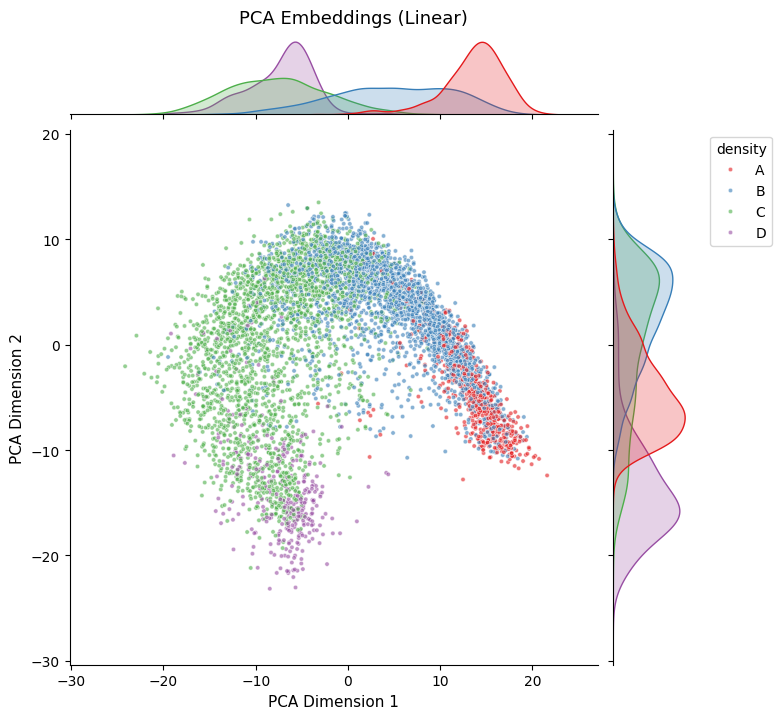

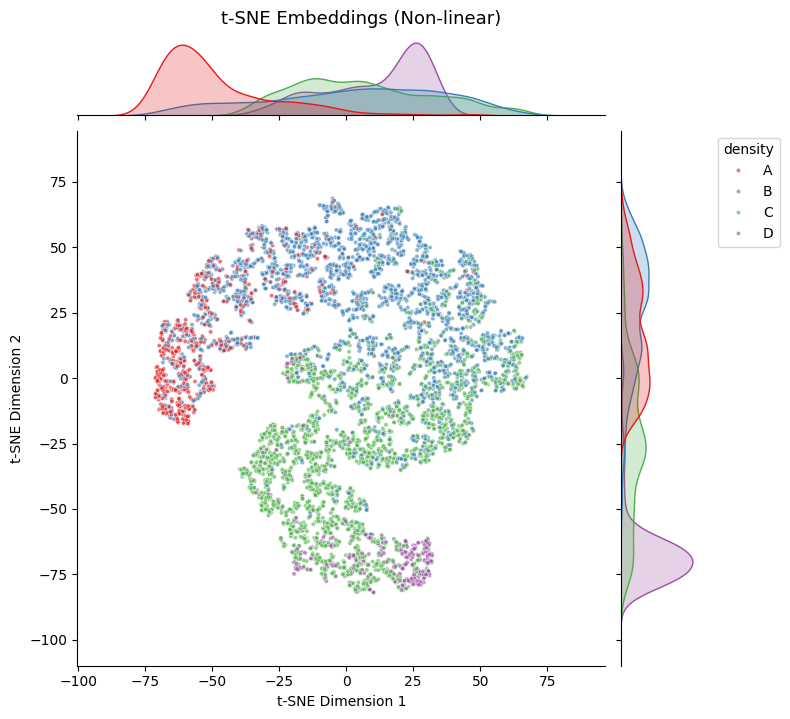

In [ ]:
# PCA (linear projection)
g1 = sns.jointplot(data=df, x='pca_1', y='pca_2', hue='density',
                   hue_order=sorted(df['density'].unique()),
                   alpha=alpha, marker=marker, s=markersize,
                   palette=density_palette,
                   height=7, ratio=6,
                   marginal_kws={'common_norm': False})
g1.ax_joint.set_xlabel('PCA Dimension 1', fontsize=11)
g1.ax_joint.set_ylabel('PCA Dimension 2', fontsize=11)
g1.set_axis_labels('PCA Dimension 1', 'PCA Dimension 2')
plt.suptitle('PCA Embeddings (Linear)', y=1.02, fontsize=13)
sns.move_legend(g1.ax_joint, 'upper left', bbox_to_anchor=(1.2, 1))
plt.tight_layout()
plt.show()

# t-SNE (non-linear projection)
g2 = sns.jointplot(data=df, x='tsne_1', y='tsne_2', hue='density',
                   hue_order=sorted(df['density'].unique()),
                   alpha=alpha, marker=marker, s=markersize,
                   palette=density_palette,
                   height=7, ratio=6,
                   marginal_kws={'common_norm': False})
g2.set_axis_labels('t-SNE Dimension 1', 't-SNE Dimension 2')
plt.suptitle('t-SNE Embeddings (Non-linear)', y=1.02, fontsize=13)
sns.move_legend(g2.ax_joint, 'upper left', bbox_to_anchor=(1.2, 1))
plt.tight_layout()
plt.show()

### **D.2 Misclassification Analysis**

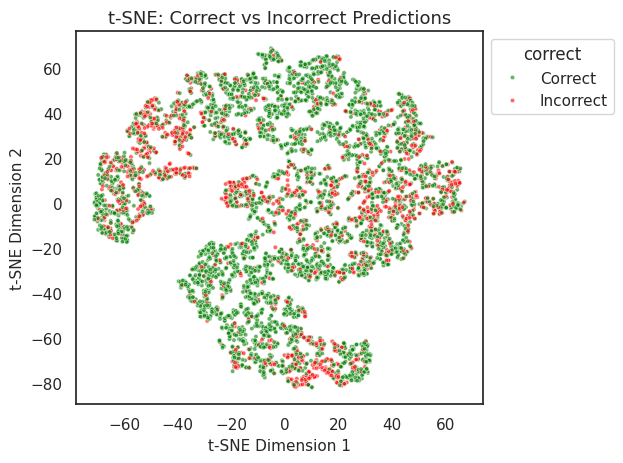

Overall error rate: 27.11%


In [ ]:
df['correct'] = (df['target'] == df['predicted_class']).map(
    {True: 'Correct', False: 'Incorrect'})

plot_scatter(data=df, hue='correct', x='tsne_1', y='tsne_2',
             palette={'Correct': 'green', 'Incorrect': 'red'},
             title='t-SNE: Correct vs Incorrect Predictions')

error_rate = (df['correct'] == 'Incorrect').sum() / len(df) * 100
print(f"Overall error rate: {error_rate:.2f}%")

### **D.3 Most Common Confusion: B→A**

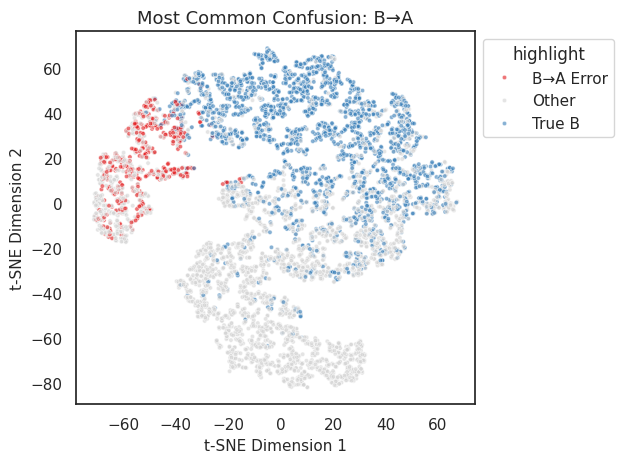

In [ ]:
df['highlight'] = 'Other'
df.loc[df['density'] == 'B', 'highlight'] = 'True B'
df.loc[(df['density'] == 'B') & (df['predicted_label'] == 'A'),
       'highlight'] = 'B→A Error'

plot_scatter(data=df, hue='highlight', x='tsne_1', y='tsne_2',
             palette={'Other': 'lightgray', 'True B': '#377eb8',
                      'B→A Error': '#e41a1c'},
             title='Most Common Confusion: B→A')

### **D.4 Metadata Analysis**

Embedding space coloured by clinical and acquisition-related attributes to probe for potential bias. The same plotting function is reused for age group, view position, laterality, and machine ID.

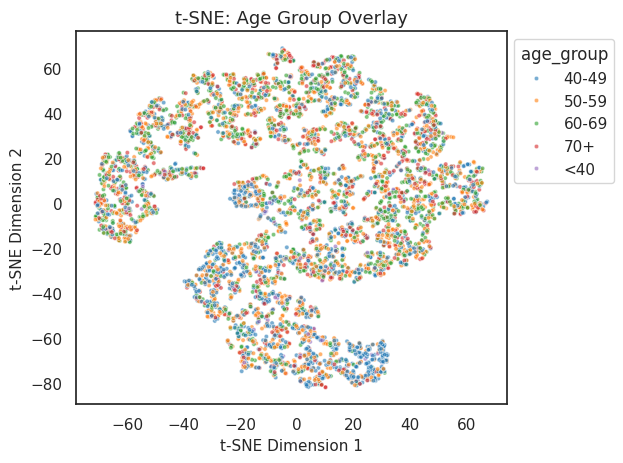

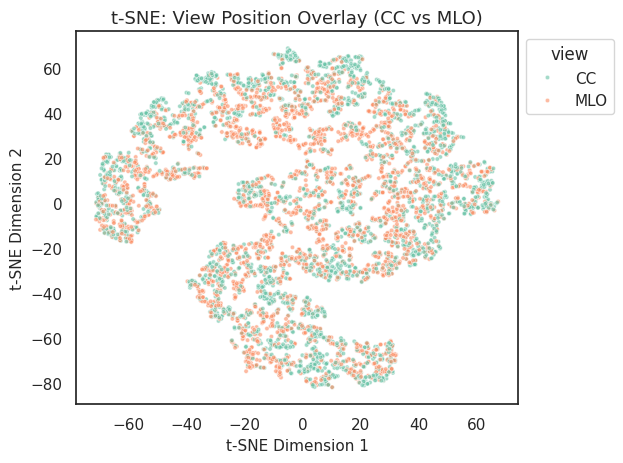

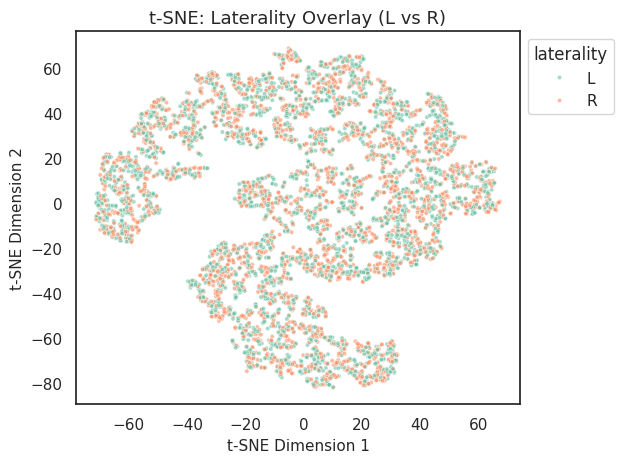

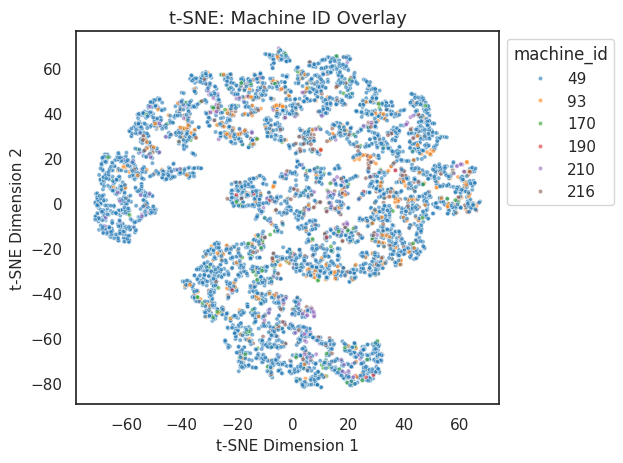

In [ ]:
# Create age group column for overlay
df['age_group'] = df['age'].apply(lambda x:
    '<40' if x < 40 else
    '40-49' if x < 50 else
    '50-59' if x < 60 else
    '60-69' if x < 70 else '70+')
# Age group
plot_scatter(data=df, hue='age_group', x='tsne_1', y='tsne_2',
             palette='tab10',
             title='t-SNE: Age Group Overlay')

# View position
plot_scatter(data=df, hue='view', x='tsne_1', y='tsne_2',
             palette='Set2',
             title='t-SNE: View Position Overlay (CC vs MLO)')

# Laterality
plot_scatter(data=df, hue='laterality', x='tsne_1', y='tsne_2',
             palette='Set2',
             title='t-SNE: Laterality Overlay (L vs R)')

# Machine ID
plot_scatter(data=df, hue='machine_id', x='tsne_1', y='tsne_2',
             palette='tab10',
             title='t-SNE: Machine ID Overlay')

### **D.5 Class Centroids in t-SNE Space**

In [ ]:
print("Class centroids in t-SNE space:")
for cls in ['A', 'B', 'C', 'D']:
    subset = df[df['density'] == cls]
    print(f"  Class {cls}: n={len(subset):4d}, "
          f"centroid=({subset['tsne_1'].mean():.2f}, "
          f"{subset['tsne_2'].mean():.2f})")

print(f"\nCorrect: {(df['correct']=='Correct').sum()} "
      f"({(df['correct']=='Correct').sum()/len(df)*100:.2f}%)")
print(f"Incorrect: {(df['correct']=='Incorrect').sum()} "
      f"({(df['correct']=='Incorrect').sum()/len(df)*100:.2f}%)")

Class centroids in t-SNE space:
  Class A: n= 628, centroid=(-48.42, 15.84)
  Class B: n=2548, centroid=(2.58, 25.38)
  Class C: n=2368, centroid=(6.71, -25.30)
  Class D: n= 321, centroid=(11.28, -65.59)

Correct: 4275 (72.89%)
Incorrect: 1590 (27.11%)
